In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

count         5.000000
mean     123000.000000
std      210765.272282
min       25000.000000
25%       28000.000000
50%       30000.000000
75%       32000.000000
max      500000.000000
Name: Salary, dtype: float64


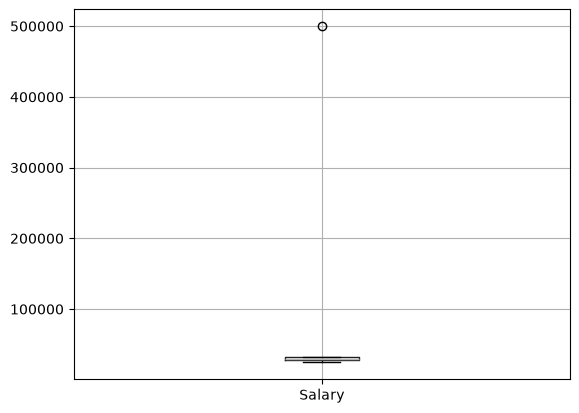

In [3]:
df = pd.DataFrame({
    "Salary": [25000, 28000, 30000, 32000, 500000]
})

# Summary statistics
print(df["Salary"].describe())

# Box plot
df.boxplot(column="Salary")
plt.show()

In [4]:
import numpy as np

data = np.array([10, 12, 13, 14, 15, 16, 100])

q1 = np.percentile(data, 25)
q3 = np.percentile(data, 75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = data[(data < lower) | (data > upper)]

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Outliers:", outliers)

Lower bound: 8.0
Upper bound: 20.0
Outliers: [100]


In [5]:
from sklearn.ensemble import IsolationForest

X = [[10], [12], [13], [14], [15], [16], [100]]

model = IsolationForest(
    contamination="auto",
    random_state=42
)

labels = model.fit_predict(X)

# -1 = outlier, 1 = inlier
print(labels)

[-1  1  1  1  1  1 -1]


In [7]:
#Z score 

import numpy as np
data=np.array([10,12,13,24,55,66,777])
mean=np.mean(data)
std=np.std(data)

z_scores=(data-mean)/std
outliers=data[np.abs(z_scores)>3]
print(z_scores)
print(outliers)
print(mean)

[-0.48326258 -0.47563499 -0.47182119 -0.42986942 -0.31164171 -0.26968994
  2.44191983]
[]
136.71428571428572


In [8]:

from sklearn.preprocessing import StandardScaler

X = np.array([[10], [12], [13], [14], [15], [16], [100]])

scaler = StandardScaler()
z_scores = scaler.fit_transform(X).ravel()

mask = np.abs(z_scores) <= 3
X_clean = X[mask]

print("Flagged:", X[~mask].ravel())
print("Cleaned:", X_clean.ravel())

Flagged: []
Cleaned: [ 10  12  13  14  15  16 100]


In [9]:

data = np.array([10, 12, 13, 14, 15, 16, 18, 100])

q1 = np.percentile(data, 25)
q3 = np.percentile(data, 75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

In [10]:
data = np.array([10, 12, 14, 16, 18, 20, 22, 100])

q1 = np.percentile(data, 25)
q3 = np.percentile(data, 75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

mask = (data >= lower) & (data <= upper)

print("Lower boundary:", lower)
print("Upper boundary:", upper)
print("Outliers:", data[~mask])
print("After removal:", data[mask])

Lower boundary: 3.0
Upper boundary: 31.0
Outliers: [100]
After removal: [10 12 14 16 18 20 22]


In [11]:
import numpy as np
from sklearn.model_selection import train_test_split

X = np.array([[10], [12], [14], [16], [18], [20], [22], [100]])

X_train, X_test = train_test_split(
    X, test_size=0.25, random_state=42
)

# Learn boundaries from training data only
q1 = np.percentile(X_train[:, 0], 25)
q3 = np.percentile(X_train[:, 0], 75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

train_mask = (
    (X_train[:, 0] >= lower) &
    (X_train[:, 0] <= upper)
)

X_train_clean = X_train[train_mask]

# Apply the same learned boundaries to test data
test_mask = (
    (X_test[:, 0] >= lower) &
    (X_test[:, 0] <= upper)
)

print("Cleaned training data:", X_train_clean.ravel())
print("Test outlier flags:", (~test_mask))

Cleaned training data: [10 14 18 16 22]
Test outlier flags: [False False]


In [12]:
data = np.array([10, 12, 13, 14, 15, 16, 18, 100])

lower = np.percentile(data, 5)
upper = np.percentile(data, 95)

# Winsorization
capped = np.clip(data, lower, upper)

print("Lower cutoff:", lower)
print("Upper cutoff:", upper)
print("Winsorized:", capped)

Lower cutoff: 10.7
Upper cutoff: 71.29999999999995
Winsorized: [10.7 12.  13.  14.  15.  16.  18.  71.3]


In [13]:
import numpy as np

data = np.array([5, 20, 30, 40, 100])

lower = 10
upper = 90

# Cap extreme values
winsorized = np.clip(data, lower, upper)

# Alternatively, remove extreme values
trimmed = data[(data >= lower) & (data <= upper)]

print("Original:", data)
print("Winsorized:", winsorized)
print("Trimmed:", trimmed)

Original: [  5  20  30  40 100]
Winsorized: [10 20 30 40 90]
Trimmed: [20 30 40]


In [14]:
df = pd.DataFrame({
    "Full_Name": ["Rahul Sharma", "Priya Patel"],
    "Price": [100, 200],
    "Quantity": [2, 3]
})

# Feature splitting
df[["First_Name", "Last_Name"]] = (
    df["Full_Name"].str.split(" ", n=1, expand=True)
)

# Feature construction
df["Total_Cost"] = df["Price"] * df["Quantity"]

print(df)

      Full_Name  Price  Quantity First_Name Last_Name  Total_Cost
0  Rahul Sharma    100         2      Rahul    Sharma         200
1   Priya Patel    200         3      Priya     Patel         600


In [15]:
df = pd.DataFrame({
    "Date": ["2026-01-15", "2026-03-20"],
    "Full_Name": ["Amit Shah", "Neha Joshi"],
    "Price": [100, 200],
    "Quantity": [2, 3]
})

# Split names
df[["First_Name", "Last_Name"]] = (
    df["Full_Name"].str.split(" ", n=1, expand=True)
)

# Construct total cost
df["Total_Cost"] = df["Price"] * df["Quantity"]

# Construct date features
df["Date"] = pd.to_datetime(df["Date"])
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day

print(df)

        Date   Full_Name  Price  Quantity First_Name Last_Name  Total_Cost  \
0 2026-01-15   Amit Shah    100         2       Amit      Shah         200   
1 2026-03-20  Neha Joshi    200         3       Neha     Joshi         600   

   Month  Day  
0      1   15  
1      3   20  


In [16]:
bins_per_feature = 10

for dimensions in [1, 2, 3, 5, 8, 10]:
    regions = bins_per_feature ** dimensions
    print(f"{dimensions} dimensions: {regions:,} regions")

1 dimensions: 10 regions
2 dimensions: 100 regions
3 dimensions: 1,000 regions
5 dimensions: 100,000 regions
8 dimensions: 100,000,000 regions
10 dimensions: 10,000,000,000 regions


In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    StandardScaler(),
    PCA(n_components=2)
)
